In [ ]:
#data wranling & pre-processing
import pandas as pd
import numpy as np

from itertools import cycle

import sklearn
from sklearn.model_selection import train_test_split
#cross validation
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import KFold

#model validation
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn import metrics
from sklearn.metrics import (
    confusion_matrix,accuracy_score,
    roc_auc_score,roc_curve,auc,
    classification_report,mean_absolute_error,
    mean_squared_error,cohen_kappa_score,
    log_loss,precision_score,f1_score,recall_score,fbeta_score,matthews_corrcoef)

#machine learning algorithms
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier as KNN
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier,RandomForestClassifier,VotingClassifier,AdaBoostClassifier,GradientBoostingClassifier,ExtraTreesClassifier
from sklearn.naive_bayes import GaussianNB
#from catboost import CatBoostClassifier,Pool,cv,CatBoostRegressor
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import sklearn.linear_model as lm
import xgboost as xgb
from xgboost import plot_tree,plot_importance
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import SGDClassifier
from lightgbm import LGBMClassifier
import tensorflow as tf
from tensorflow import keras
from scipy import stats # Removed interp
from scipy.interpolate import interp1d # import interp1d from scipy.interpolate
from mlxtend.classifier import EnsembleVoteClassifier
from sklearn import tree

#data visualization
import plotly.express as px
%matplotlib inline
import matplotlib.pyplot as plt
#import matplotlib as mpl
#import matplotlib.pylab as pylab
import seaborn as sns
#mpl.style.use('ggplot')
sns.set_style('white')
#pylab.rcParams['figure.figsize']=10,8

import warnings
warnings.filterwarnings('ignore')

# from matplotlib import style
# import matplotlib.pyplot as plt
# import plotly.graph_objects as go
# from matplotlib.gridspec import GridSpec
from plotly.subplots import make_subplots
# from plotly.offline import init_notebook_mode
# init_notebook_mode(connected=True)
# sns.set()
# #style.use('fivethirtyeight')
# pd.options.mode.chained_assignment = None

In [ ]:
#importing the dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df=pd.read_excel(r'/content/drive/MyDrive/Hypothyroid/HPREG_DATASET.xlsx')

In [ ]:
df.head()

,AGE,RBS,TSH,BLOOD GROUPING,S CREATININE,HbsAg,URINE R/M/E,S. Calcium,ESR,FBS,SU,PC,EC,HBA1C,RESULT
0,18,8.5,11.14,A+,1.02,NEGATIVE,NILL,5.18,26,5.17,BLUE,PLENTY,0-4,6.52,POSITIVE
1,25,8.2,2.69,B-,0.89,NEGATIVE,TRACE,8.80,34,11.21,GREEN,2025-06-08 00:00:00,2025-01-02 00:00:00,8.11,NEGATIVE
2,30,12.7,30.20,B+,1.14,NEGATIVE,NILL,8.42,22,5.80,BLUE,0-4,2025-06-08 00:00:00,2.50,NEGATIVE
3,20,5.6,29.82,O+,0.50,NEGATIVE,TRACE,9.46,17,12.76,BLUE,0-2,2025-10-12 00:00:00,2.79,NEGATIVE
4,28,4.4,5.72,0+,0.51,NEGATIVE,TRACE,5.00,24,11.34,BLUE,2025-01-02 00:00:00,14-16,2.50,POSITIVE


In [ ]:
df.tail()

,AGE,RBS,TSH,BLOOD GROUPING,S CREATININE,HbsAg,URINE R/M/E,S. Calcium,ESR,FBS,SU,PC,EC,HBA1C,RESULT
195,25,17.0,7.66,AB+,1.20,NEGATIVE,NILL,6.05,19,6.91,TRACE,0-2,2025-03-05 00:00:00,6.84,NEGATIVE
196,18,8.8,10.12,A-,1.03,NEGATIVE,TRACE,7.77,22,4.75,GREEN,2025-06-08 00:00:00,2025-03-05 00:00:00,2.50,POSITIVE
197,26,10.8,18.94,O-,1.20,NEGATIVE,TRACE,7.97,29,3.37,GREEN,2025-01-02 00:00:00,2025-07-10 00:00:00,5.64,NEGATIVE
198,26,7.4,21.69,AB+,0.65,NEGATIVE,TRACE,8.57,32,4.22,BLUE,2025-01-02 00:00:00,2025-04-06 00:00:00,5.65,NEGATIVE
199,20,6.3,7.95,A+,1.00,NEGATIVE,TRACE,8.95,23,3.73,BLUE,2025-01-02 00:00:00,2025-07-10 00:00:00,2.50,NEGATIVE


In [ ]:
print(df.columns)

Index(['AGE', 'RBS', 'TSH', 'BLOOD GROUPING', 'S CREATININE ', '    HbsAg',
       'URINE R/M/E', 'S. Calcium', 'ESR', 'FBS', 'SU', 'PC', 'EC', 'HBA1C',
       'RESULT'],
      dtype='object')


In [ ]:
status_data = df['RESULT'].value_counts()

[None, None]

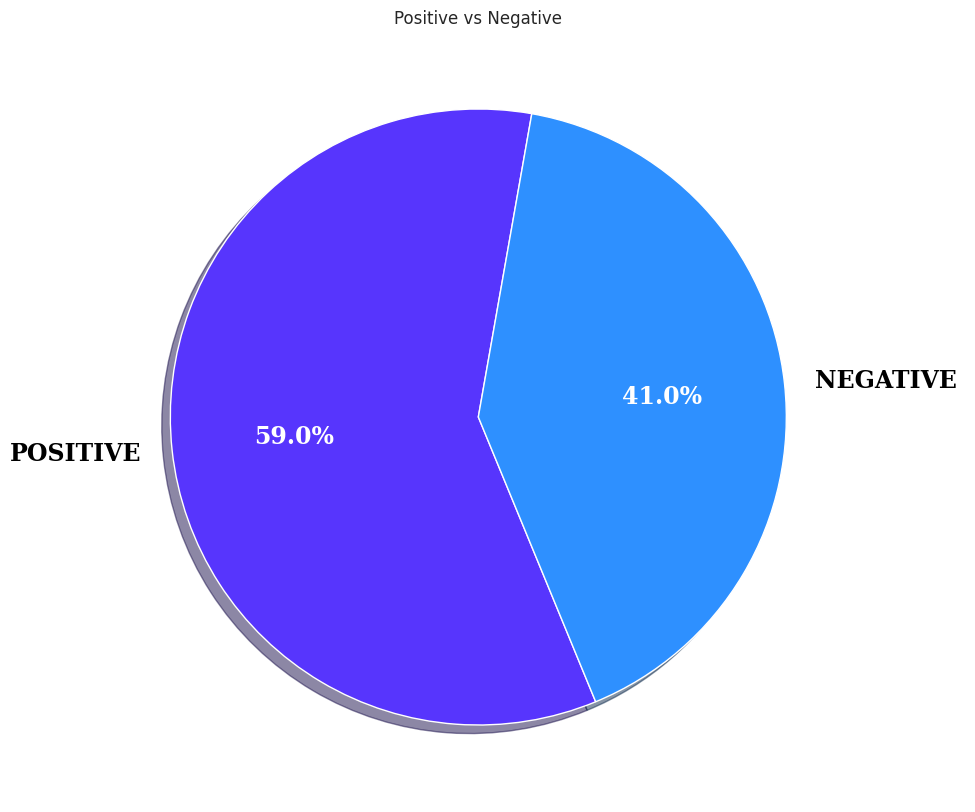

In [ ]:
explode=(0,0)
pie_colors=('#5735FD','#2E90FF','teal','orange','brown','red','pink','gray','yellow')

plt.figure(figsize=(10,10))
plt.title("Positive vs Negative")
patches,texts,pcts = plt.pie(status_data,labels=status_data.index,
                            explode=explode,colors=pie_colors,
                            shadow=True,
                            startangle=80,
                            autopct='%0.1f%%',
                            textprops={'fontsize':17,
                                      'color':'black',
                                      'weight':'bold',
                                      'family':'serif'})

plt.setp(pcts,color='white')

In [ ]:
#Checking any irregularities,unwanted or empty data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   AGE             200 non-null    int64  
 1   RBS             200 non-null    float64
 2   TSH             200 non-null    float64
 3   BLOOD GROUPING  200 non-null    object 
 4   S CREATININE    200 non-null    float64
 5       HbsAg       200 non-null    object 
 6   URINE R/M/E     200 non-null    object 
 7   S. Calcium      200 non-null    float64
 8   ESR             200 non-null    int64  
 9   FBS             200 non-null    float64
 10  SU              200 non-null    object 
 11  PC              200 non-null    object 
 12  EC              200 non-null    object 
 13  HBA1C           200 non-null    float64
 14  RESULT          200 non-null    object 
dtypes: float64(6), int64(2), object(7)
memory usage: 23.6+ KB


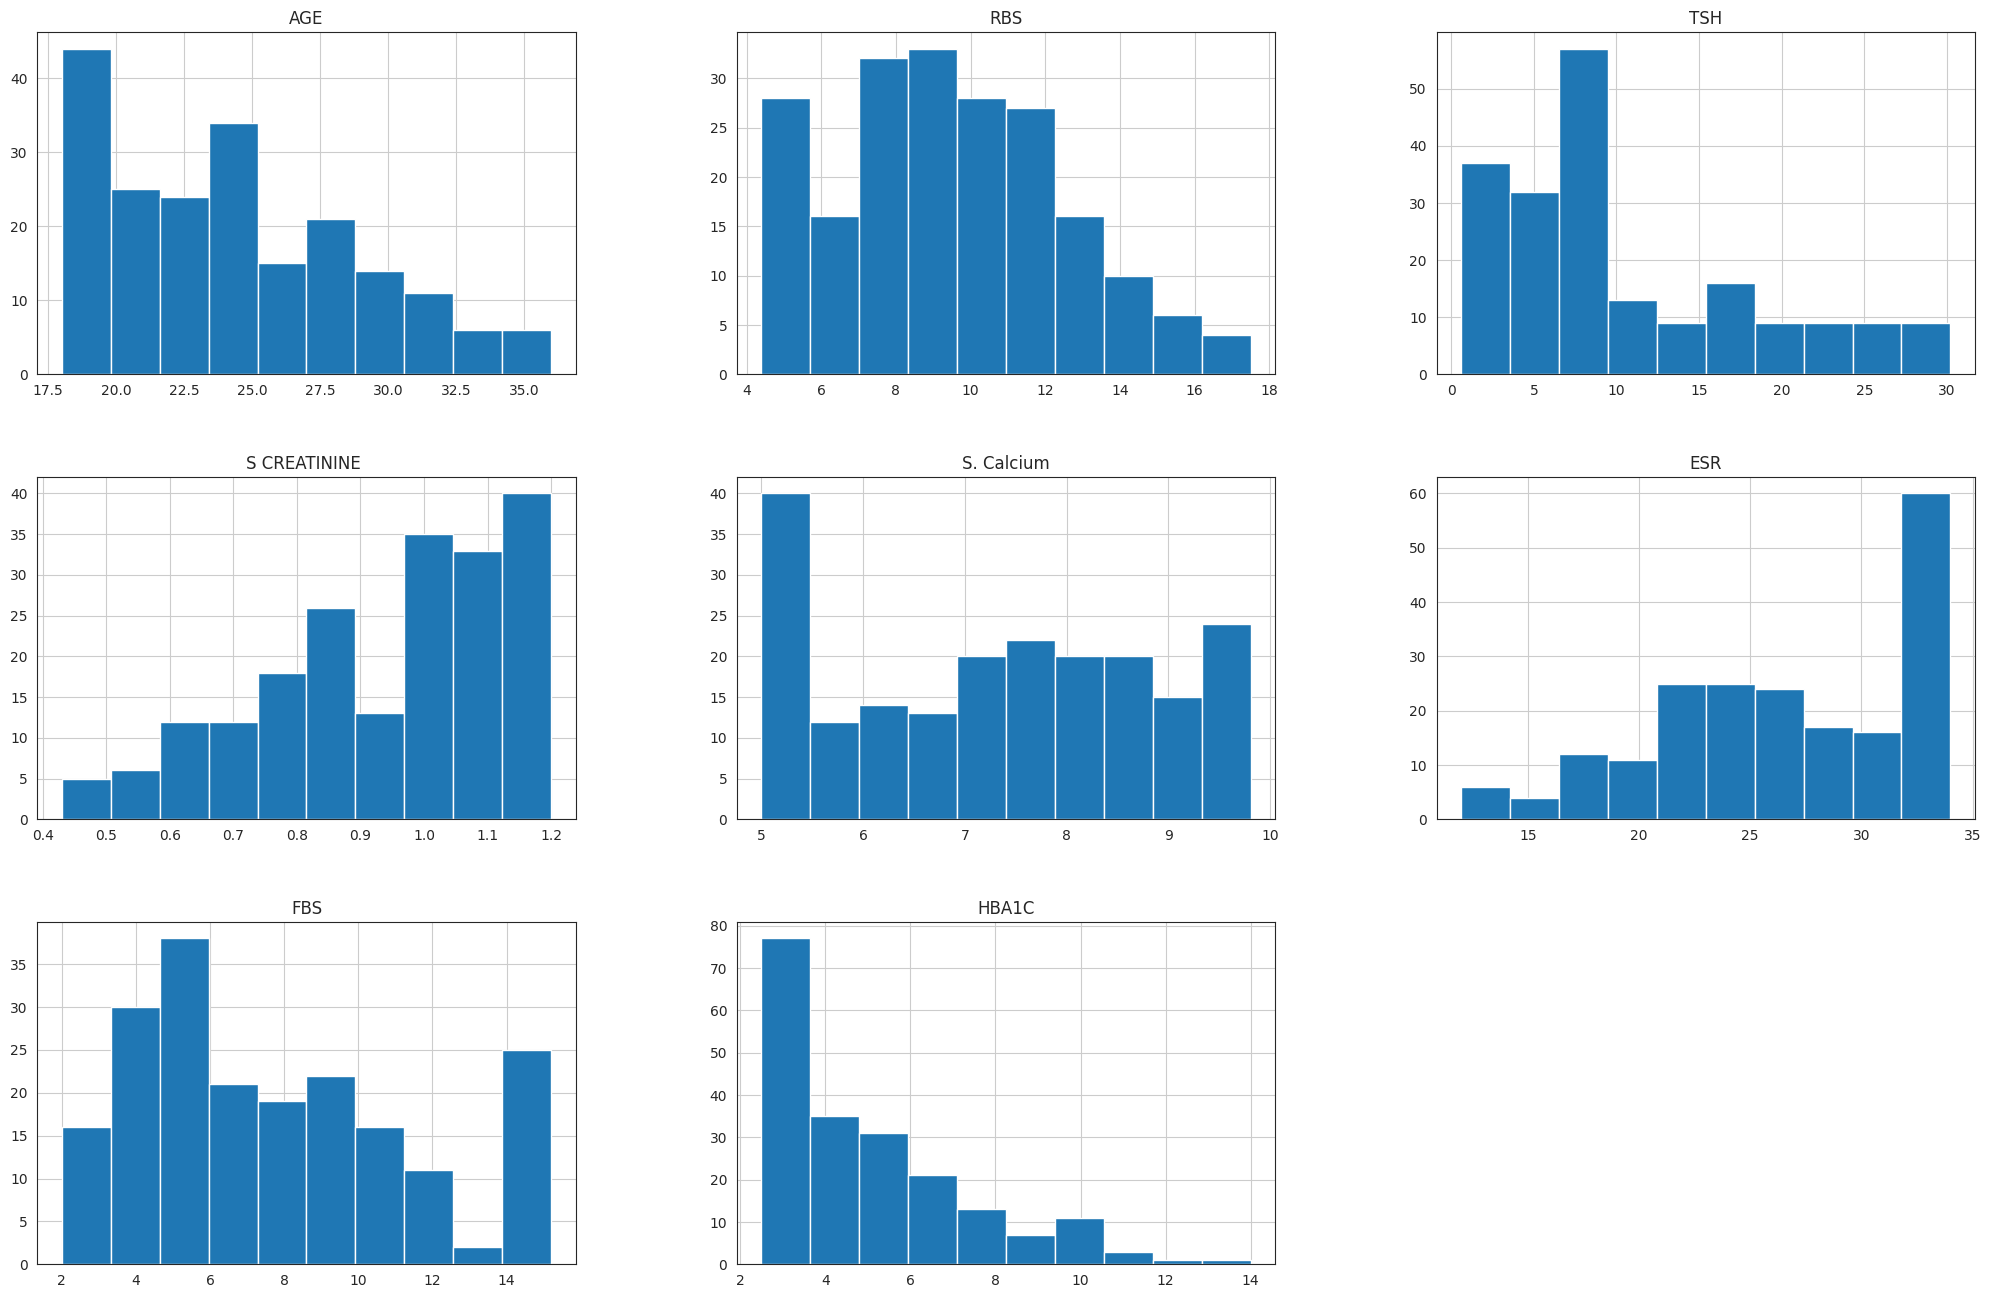

In [ ]:
#plotting the histogram of dataset
df.hist(figsize=(25,16))
plt.show()

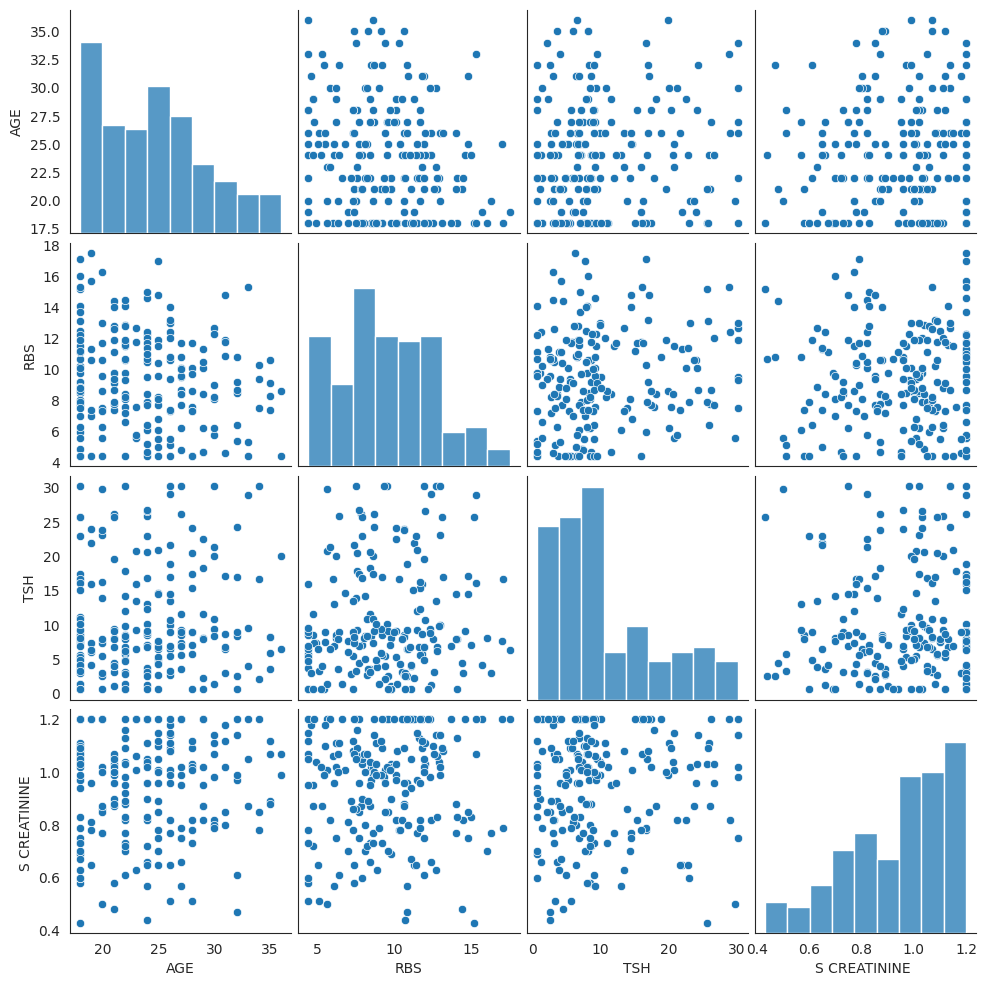

In [ ]:
#plotting pairplot using seaborn
sns.pairplot(df.iloc[:,0:6])
plt.show()

In [ ]:
df.describe().T #different central tendencies of the data

,count,mean,std,min,25%,50%,75%,max
AGE,200.0,24.07500,4.800479,18.00,20.0000,24.000,27.0000,36.00
RBS,200.0,9.44400,3.078873,4.40,7.4000,9.250,11.7000,17.50
TSH,200.0,10.59395,8.004419,0.60,4.8775,8.210,15.9325,30.20
S CREATININE,200.0,0.94355,0.198628,0.43,0.7975,0.990,1.0925,1.20
S. Calcium,200.0,7.30925,1.584165,5.00,5.8450,7.500,8.5700,9.81
ESR,200.0,26.56000,5.974519,12.00,22.0000,27.000,32.0000,34.00
FBS,200.0,7.80455,3.749447,2.00,4.8250,6.895,10.2425,15.20
HBA1C,200.0,4.97825,2.432050,2.50,2.6875,4.490,6.5200,14.00


In [ ]:
df.isnull().sum() #empty values

,0
AGE,0
RBS,0
TSH,0
BLOOD GROUPING,0
S CREATININE,0
HbsAg,0
URINE R/M/E,0
S. Calcium,0
ESR,0
FBS,0


In [ ]:
print("Number of Unique Value:")
df.nunique()

Number of Unique Value:


,0
AGE,19
RBS,96
TSH,176
BLOOD GROUPING,9
S CREATININE,58
HbsAg,2
URINE R/M/E,3
S. Calcium,130
ESR,22
FBS,170


In [ ]:
import missingno as msno

<Axes: >

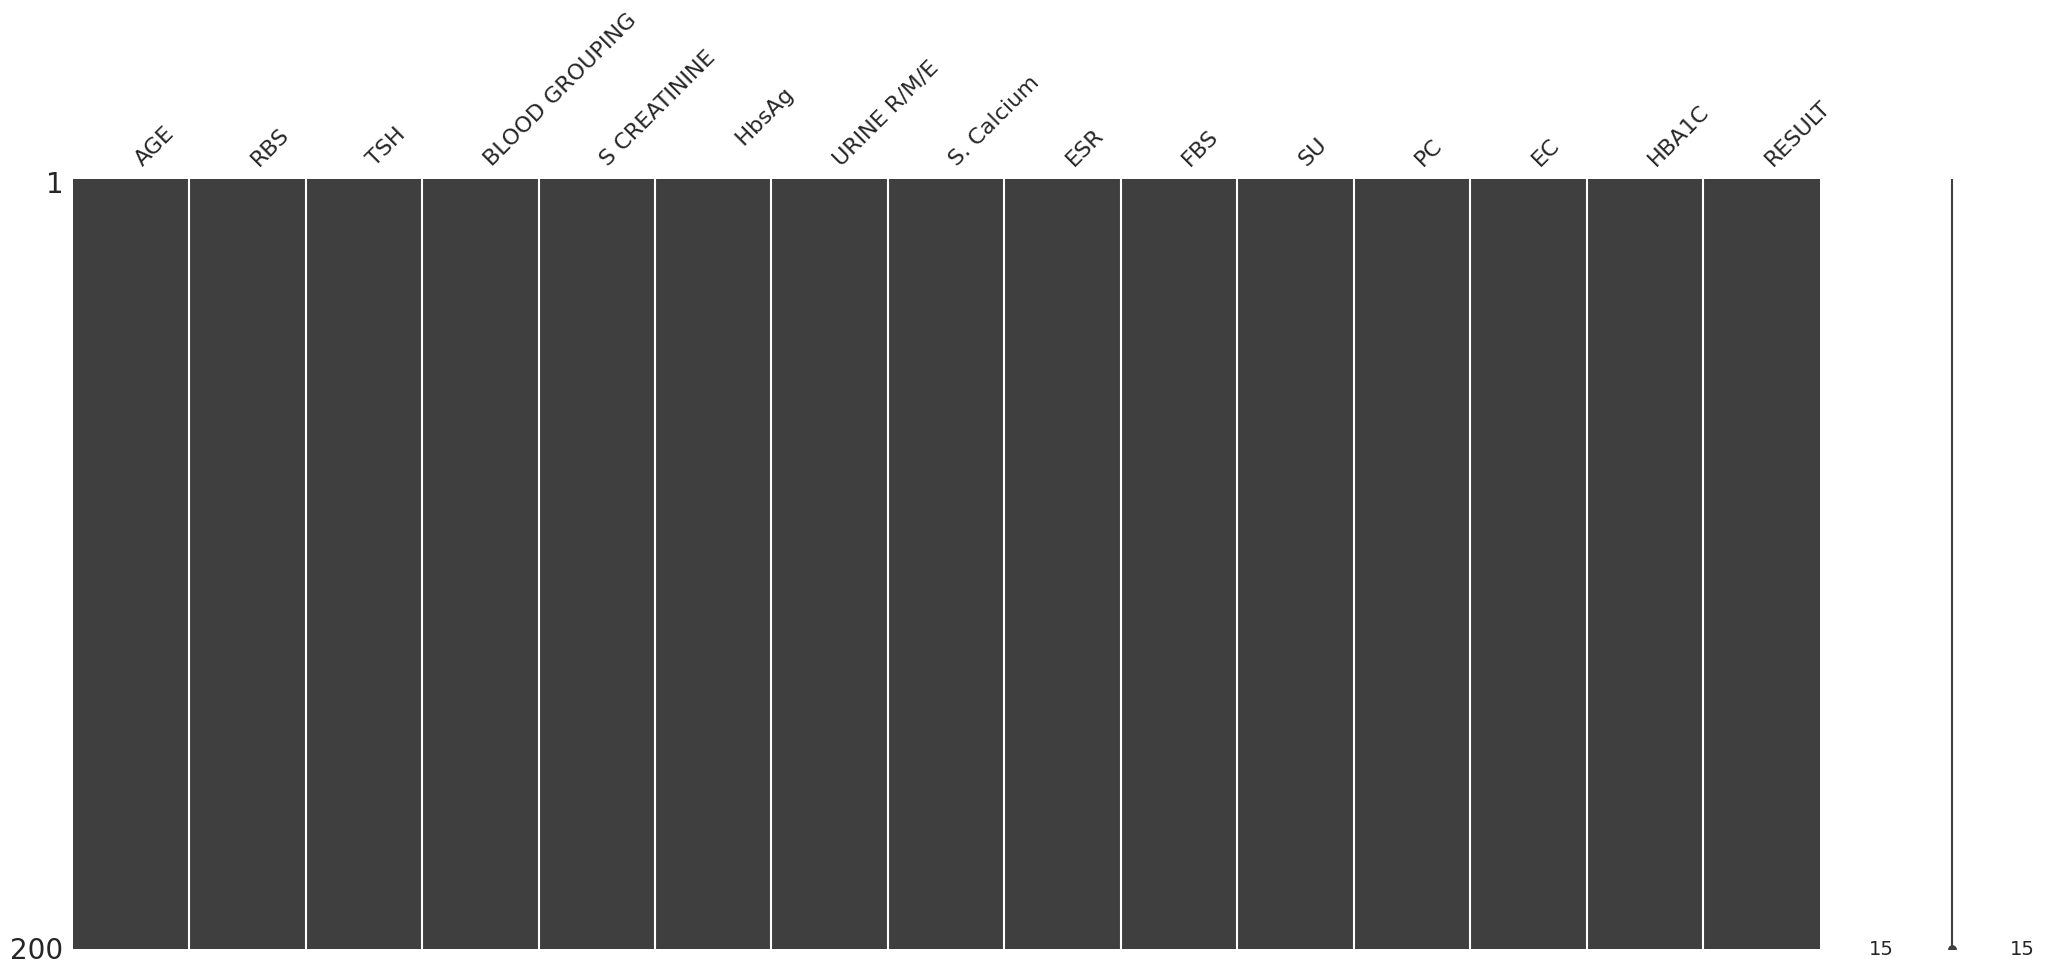

In [ ]:
msno.matrix(df)

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create a LabelEncoder object
le = LabelEncoder()

# Identify object columns
object_cols = df.select_dtypes(include='object').columns

# Iterate through each object column and apply label encoding
for col in object_cols:
    # Convert all values to string type before label encoding to handle mixed types
    df[col] = df[col].astype(str)
    df[col] = le.fit_transform(df[col])

print("Categorical columns converted to numerical format.")
df.head()

Categorical columns converted to numerical format.


,AGE,RBS,TSH,BLOOD GROUPING,S CREATININE,HbsAg,URINE R/M/E,S. Calcium,ESR,FBS,SU,PC,EC,HBA1C,RESULT
0,18,8.5,11.14,1,1.02,0,0,5.18,26,5.17,0,7,1,6.52,1
1,25,8.2,2.69,6,0.89,1,1,8.80,34,11.21,2,6,5,8.11,0
2,30,12.7,30.20,5,1.14,0,0,8.42,22,5.80,0,2,20,2.50,0
3,20,5.6,29.82,7,0.50,1,1,9.46,17,12.76,0,0,25,2.79,0
4,28,4.4,5.72,0,0.51,1,1,5.00,24,11.34,0,3,3,2.50,1


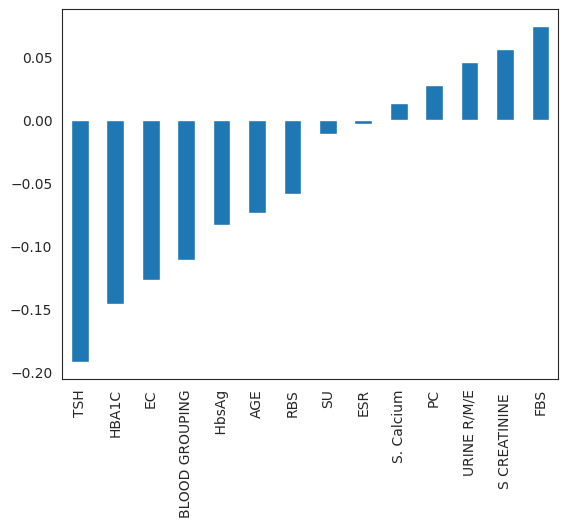

In [ ]:
df.corr()['RESULT'][:-1].sort_values().plot(kind='bar')
plt.show()

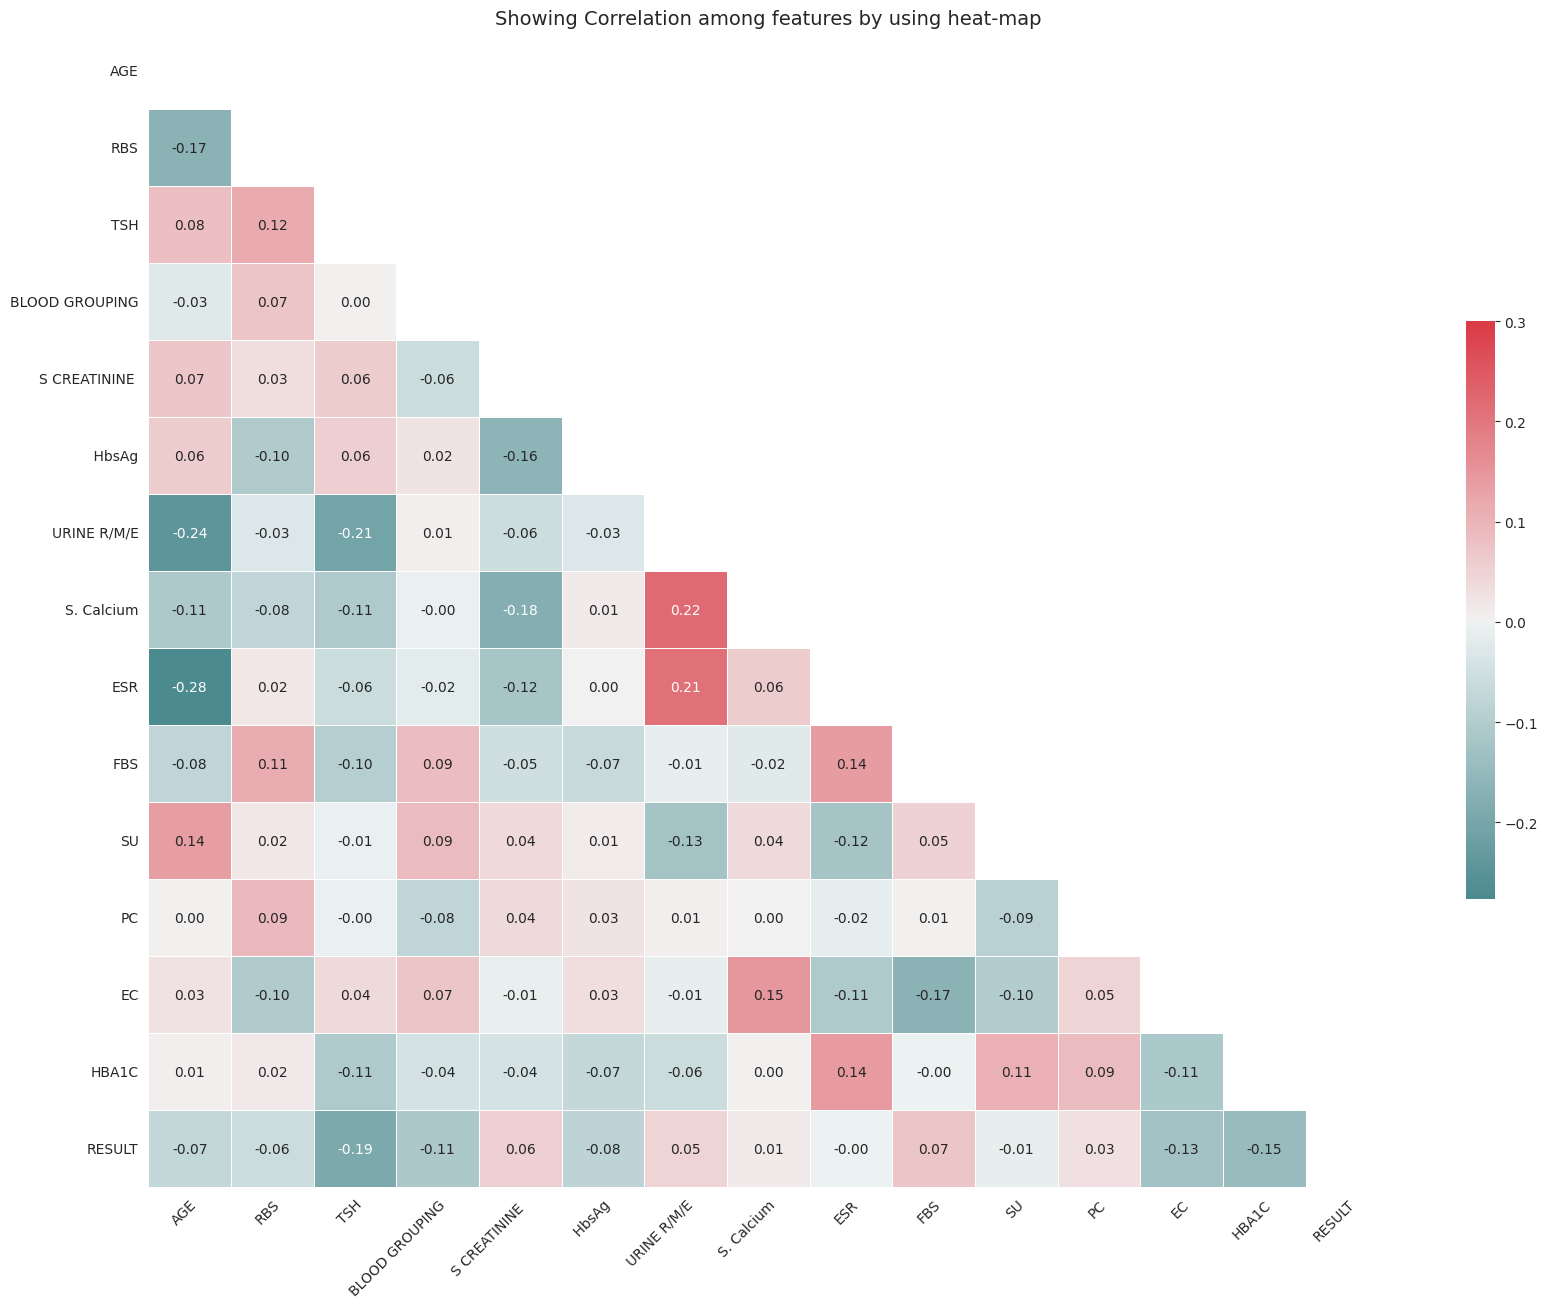

In [ ]:
correl=df.corr()
cmap = sns.diverging_palette(200,10,as_cmap=True)

# Change np.bool to bool
mask = np.zeros_like(correl,dtype=bool)

mask[np.triu_indices_from(mask)]=True
f,ax = plt.subplots(figsize=(20,15))
sns.heatmap(correl,mask=mask,cmap=cmap,vmax=0.3,center=0,annot=True,fmt='.2f',linewidths=0.5,cbar_kws={"shrink":.5});
plt.xticks(rotation=45,ha="right",rotation_mode='anchor')
plt.title('Showing Correlation among features by using heat-map',fontsize=14)
plt.show()

In [ ]:
numerical_features=[feature for feature in df.columns if ((df[feature].dtypes != '0') & (feature not in ['status']))]
print('Number of numerical variables: ',len(numerical_features))

Number of numerical variables:  15


In [ ]:
df1=df[numerical_features]

In [ ]:
df1.head()

,AGE,RBS,TSH,BLOOD GROUPING,S CREATININE,HbsAg,URINE R/M/E,S. Calcium,ESR,FBS,SU,PC,EC,HBA1C,RESULT
0,18,8.5,11.14,1,1.02,0,0,5.18,26,5.17,0,7,1,6.52,1
1,25,8.2,2.69,6,0.89,1,1,8.80,34,11.21,2,6,5,8.11,0
2,30,12.7,30.20,5,1.14,0,0,8.42,22,5.80,0,2,20,2.50,0
3,20,5.6,29.82,7,0.50,1,1,9.46,17,12.76,0,0,25,2.79,0
4,28,4.4,5.72,0,0.51,1,1,5.00,24,11.34,0,3,3,2.50,1


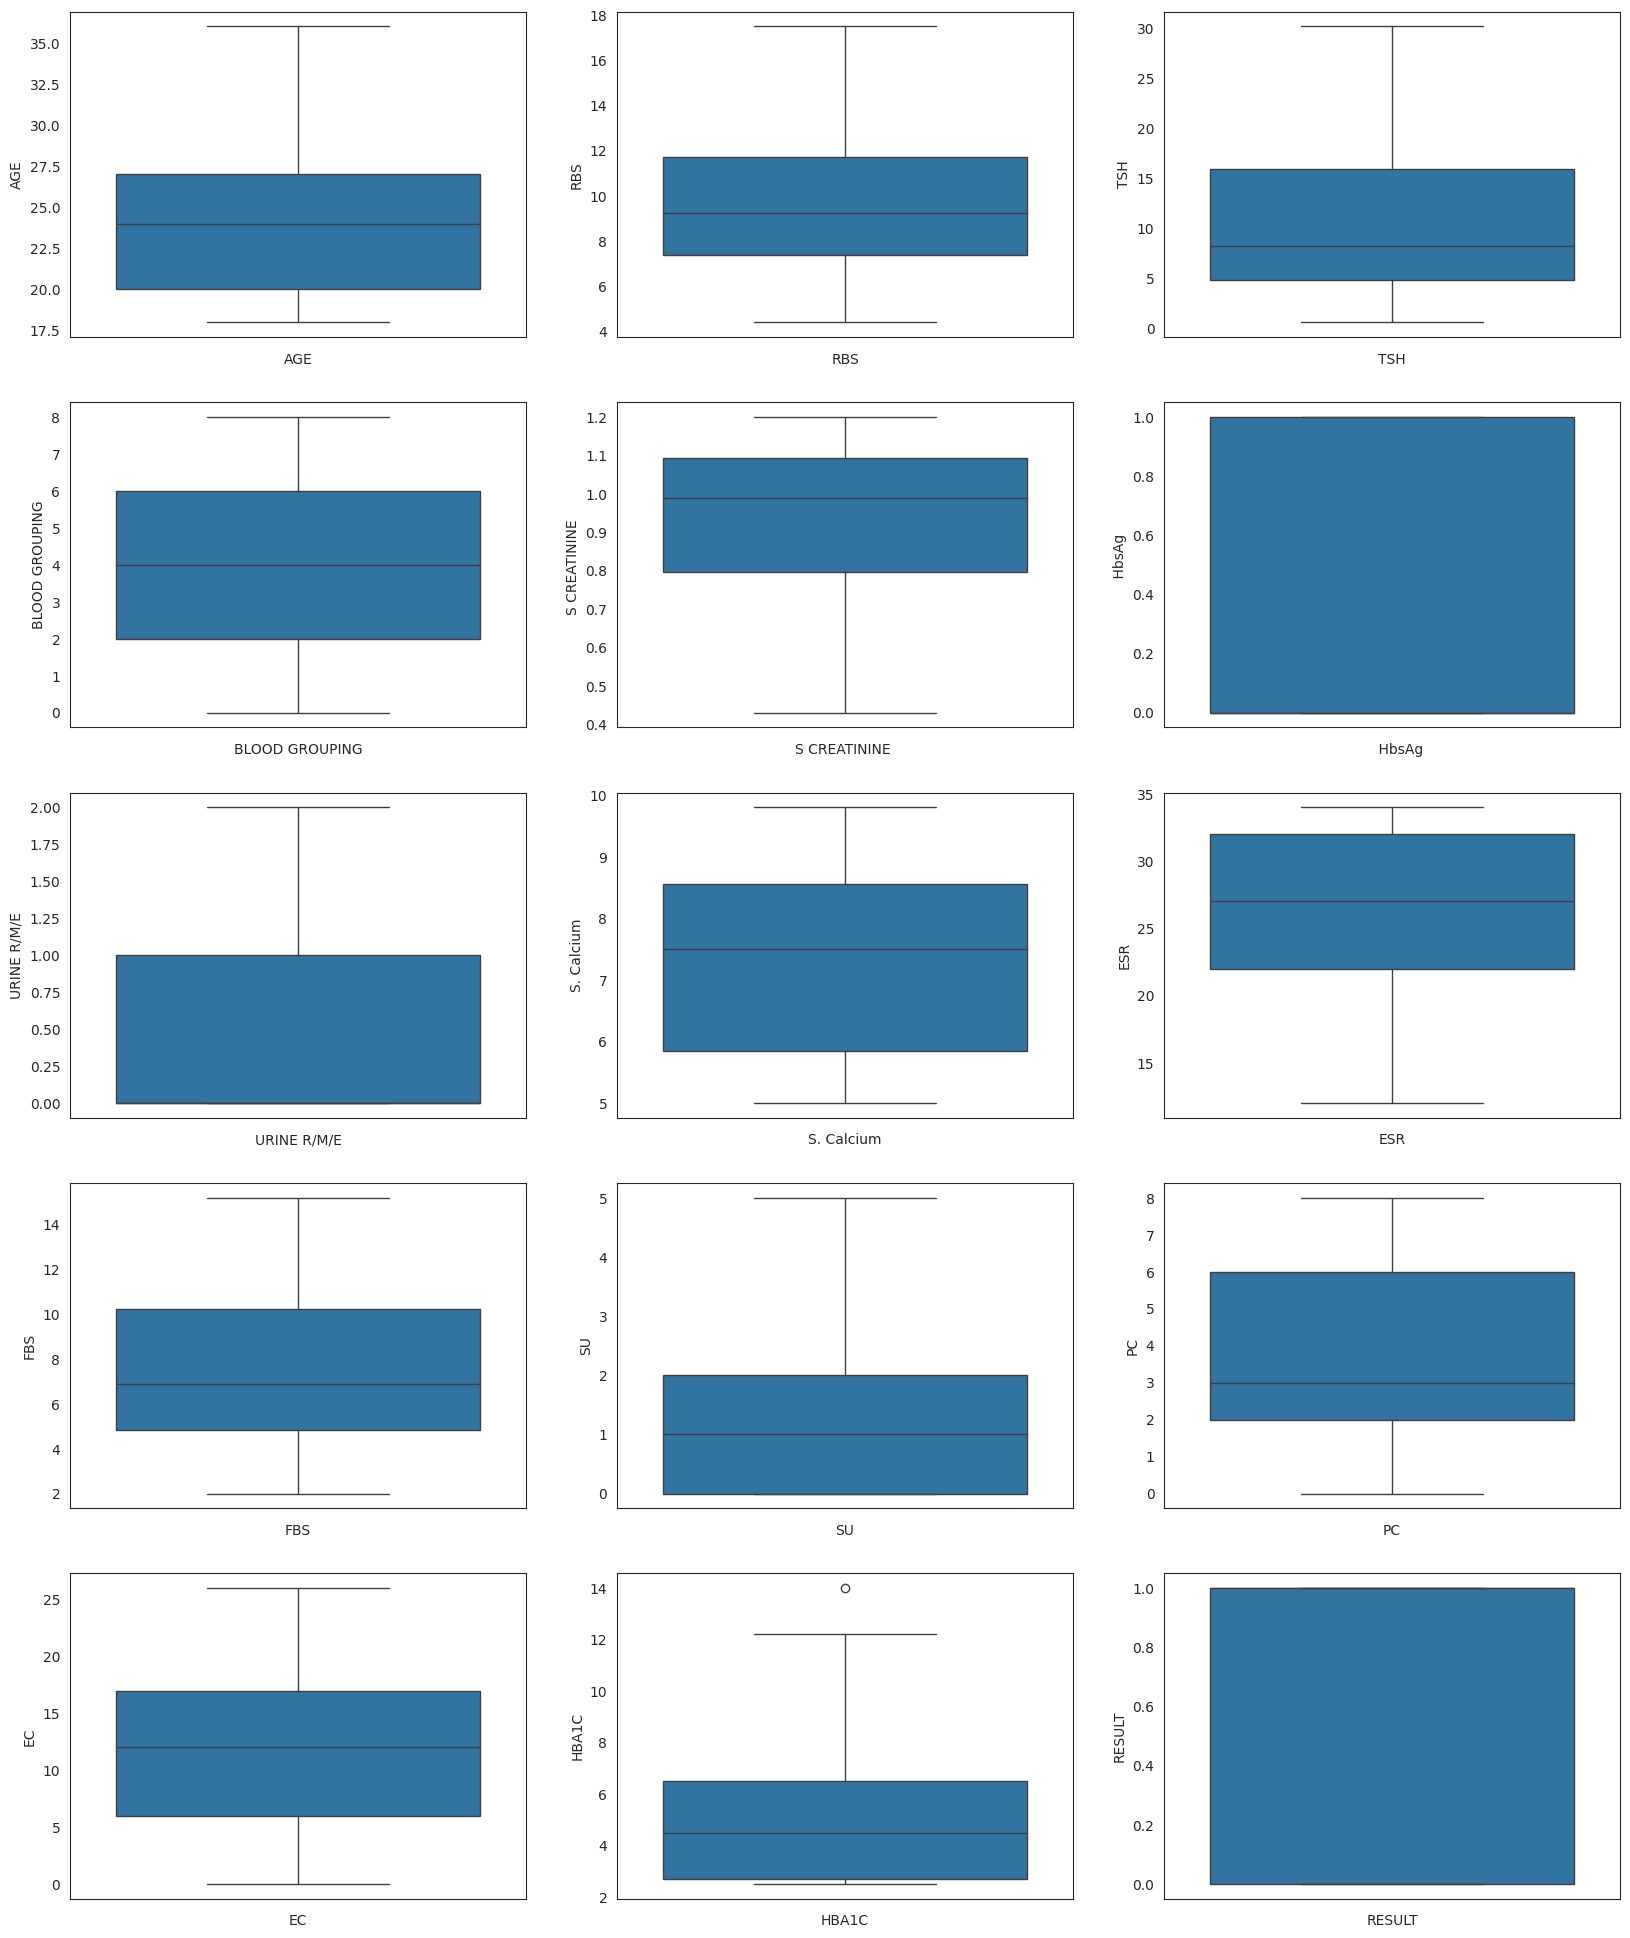

In [ ]:
plt.figure(figsize=(20,60),facecolor='white')
plotnumber=1
for numerical_feature in numerical_features:
    ax=plt.subplot(12,3,plotnumber)
    sns.boxplot(df1[numerical_feature])
    plt.xlabel(numerical_feature)
    plotnumber+=1
plt.show()

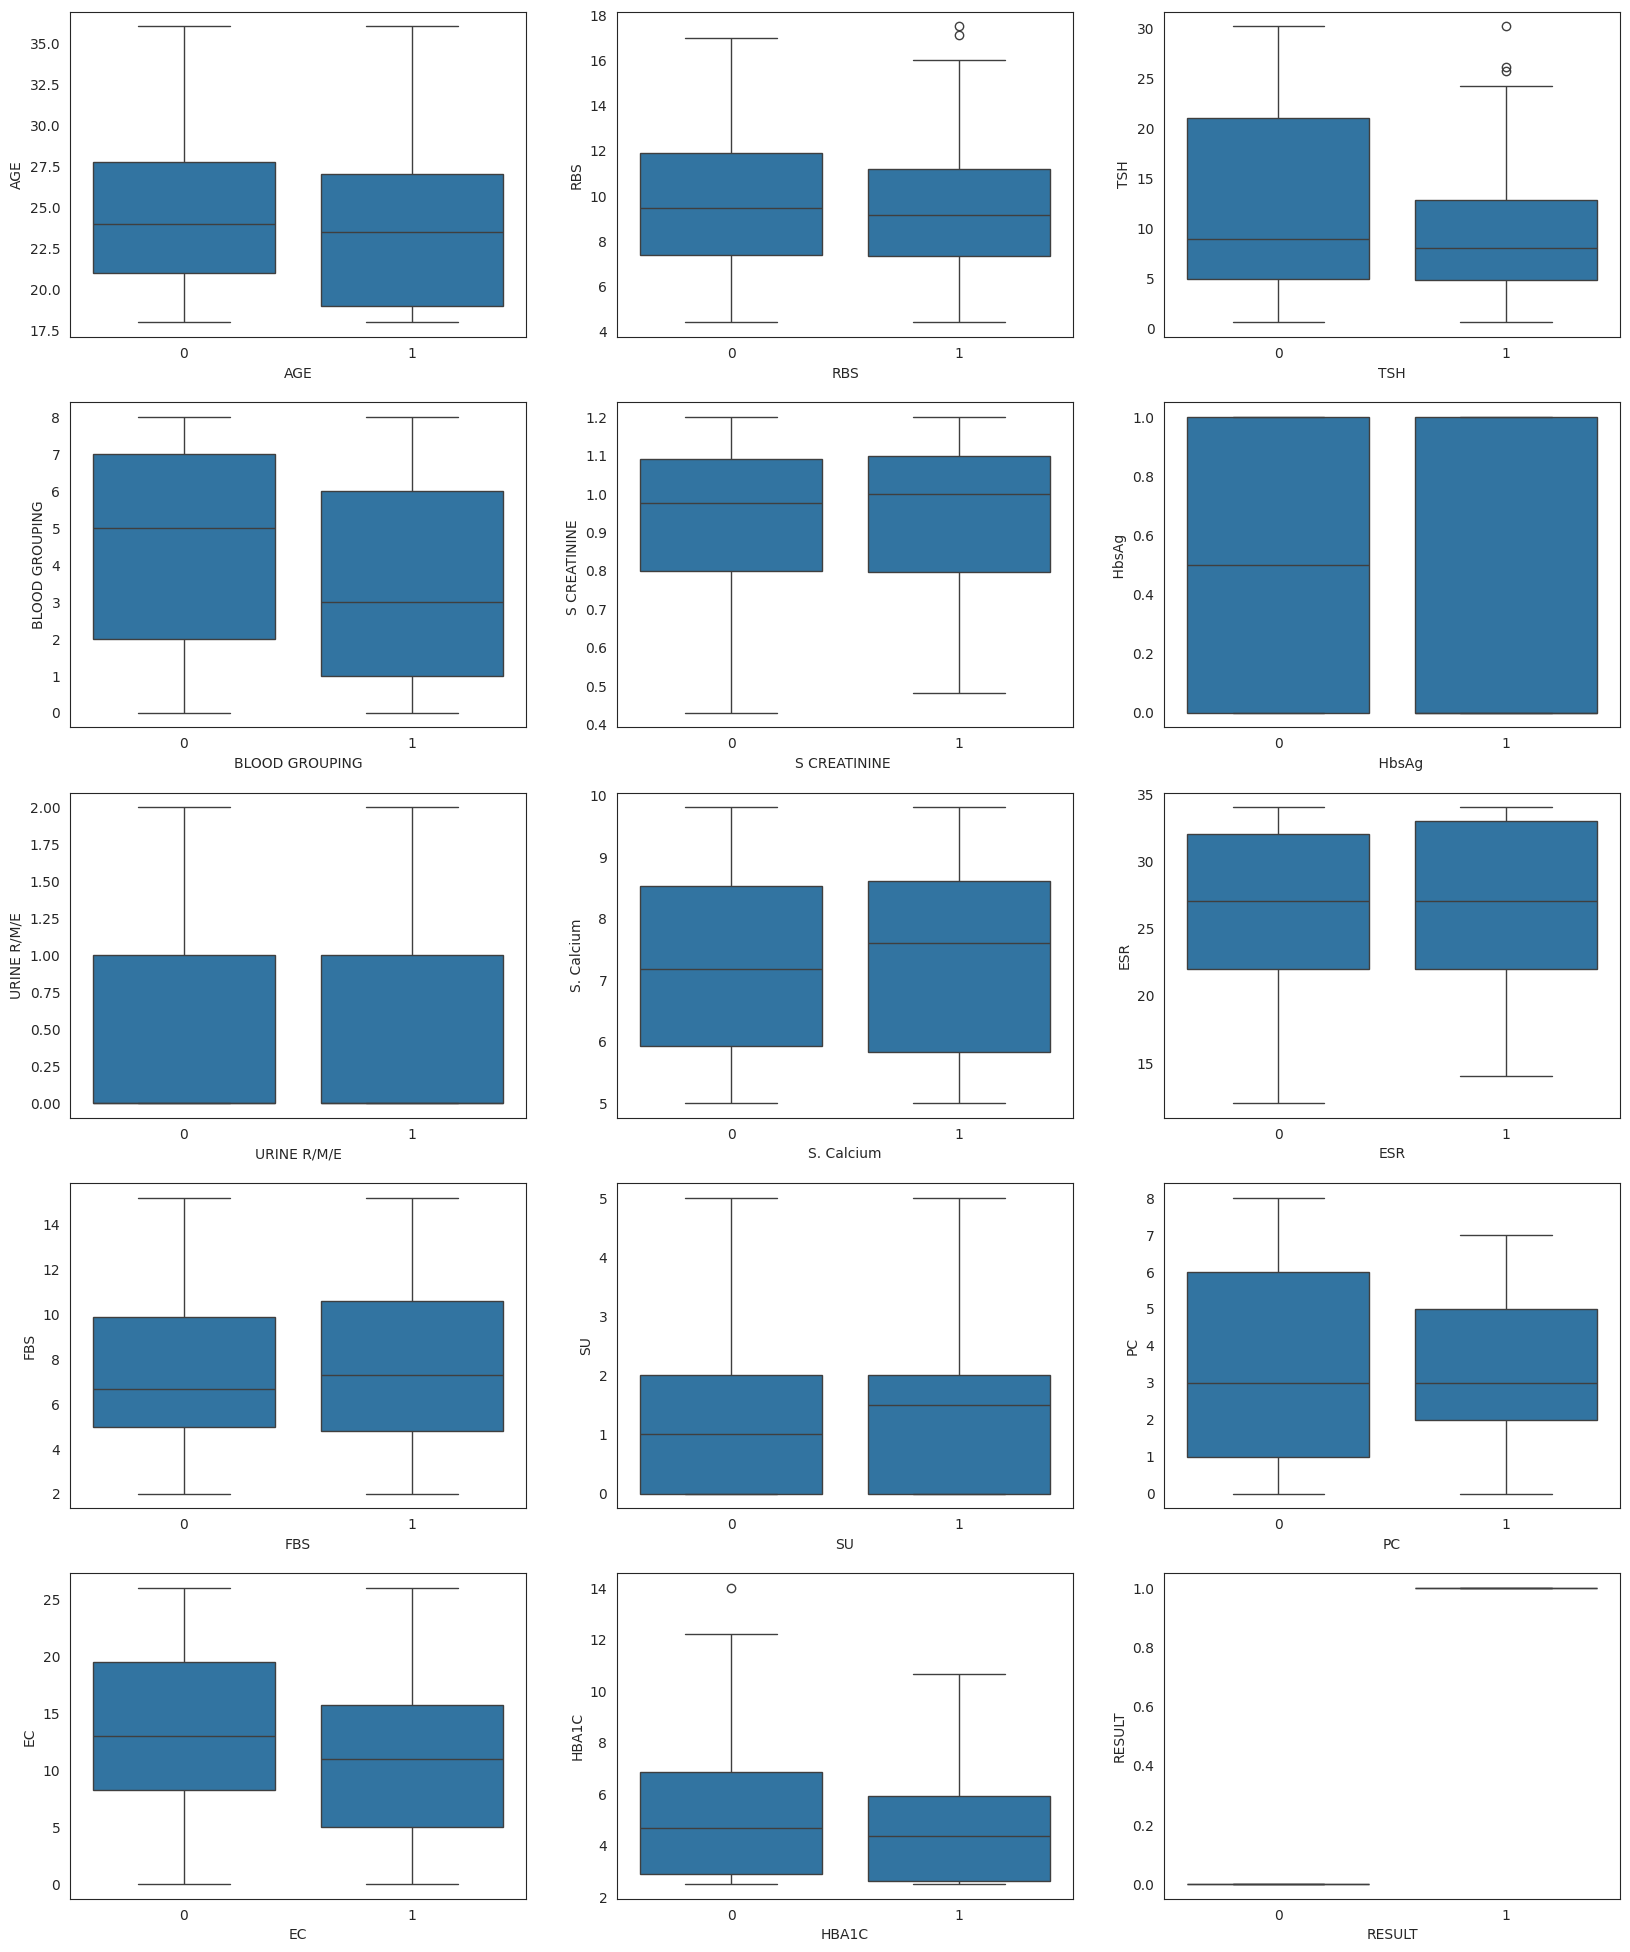

In [ ]:
plt.figure(figsize=(20,60),facecolor='white')
plotnumber=1
for numerical_feature in numerical_features:
    ax=plt.subplot(12,3,plotnumber)
    sns.boxplot(x="RESULT",y=numerical_feature,data=df)
    plt.xlabel(numerical_feature)
    plotnumber+=1
plt.show()

In [ ]:
#mean is affected by outlier so i am using median for replacing outliers
floate_col = df1.select_dtypes([np.number]).columns
floate_col

Index(['AGE', 'RBS', 'TSH', 'BLOOD GROUPING', 'S CREATININE ', '    HbsAg',
       'URINE R/M/E', 'S. Calcium', 'ESR', 'FBS', 'SU', 'PC', 'EC', 'HBA1C',
       'RESULT'],
      dtype='object')

In [ ]:
for i in floate_col:
    print(i)
    print("*"*65)
    print(df1[i].max())
    print(df1[i].min())
    print("="*65)

AGE
*****************************************************************
36
18
RBS
*****************************************************************
17.5
4.4
TSH
*****************************************************************
30.2
0.6
BLOOD GROUPING
*****************************************************************
8
0
S CREATININE 
*****************************************************************
1.2
0.43
    HbsAg
*****************************************************************
1
0
URINE R/M/E
*****************************************************************
2
0
S. Calcium
*****************************************************************
9.81
5.0
ESR
*****************************************************************
34
12
FBS
*****************************************************************
15.2
2.0
SU
*****************************************************************
5
0
PC
*****************************************************************
8
0
EC
****************************************

In [ ]:
for i in floate_col:
    q3=df1[i].quantile(0.75)
    q1=df1[i].quantile(0.25)
    iqr=q3-q1
    upper=q3 + ( 1.5 * iqr)
    lower=q1 - ( 1.5 * iqr)
    median = df1[i].median()
    df1[i]=df1[i].apply(lambda x: median if (x<lower) | (x>upper) else x)

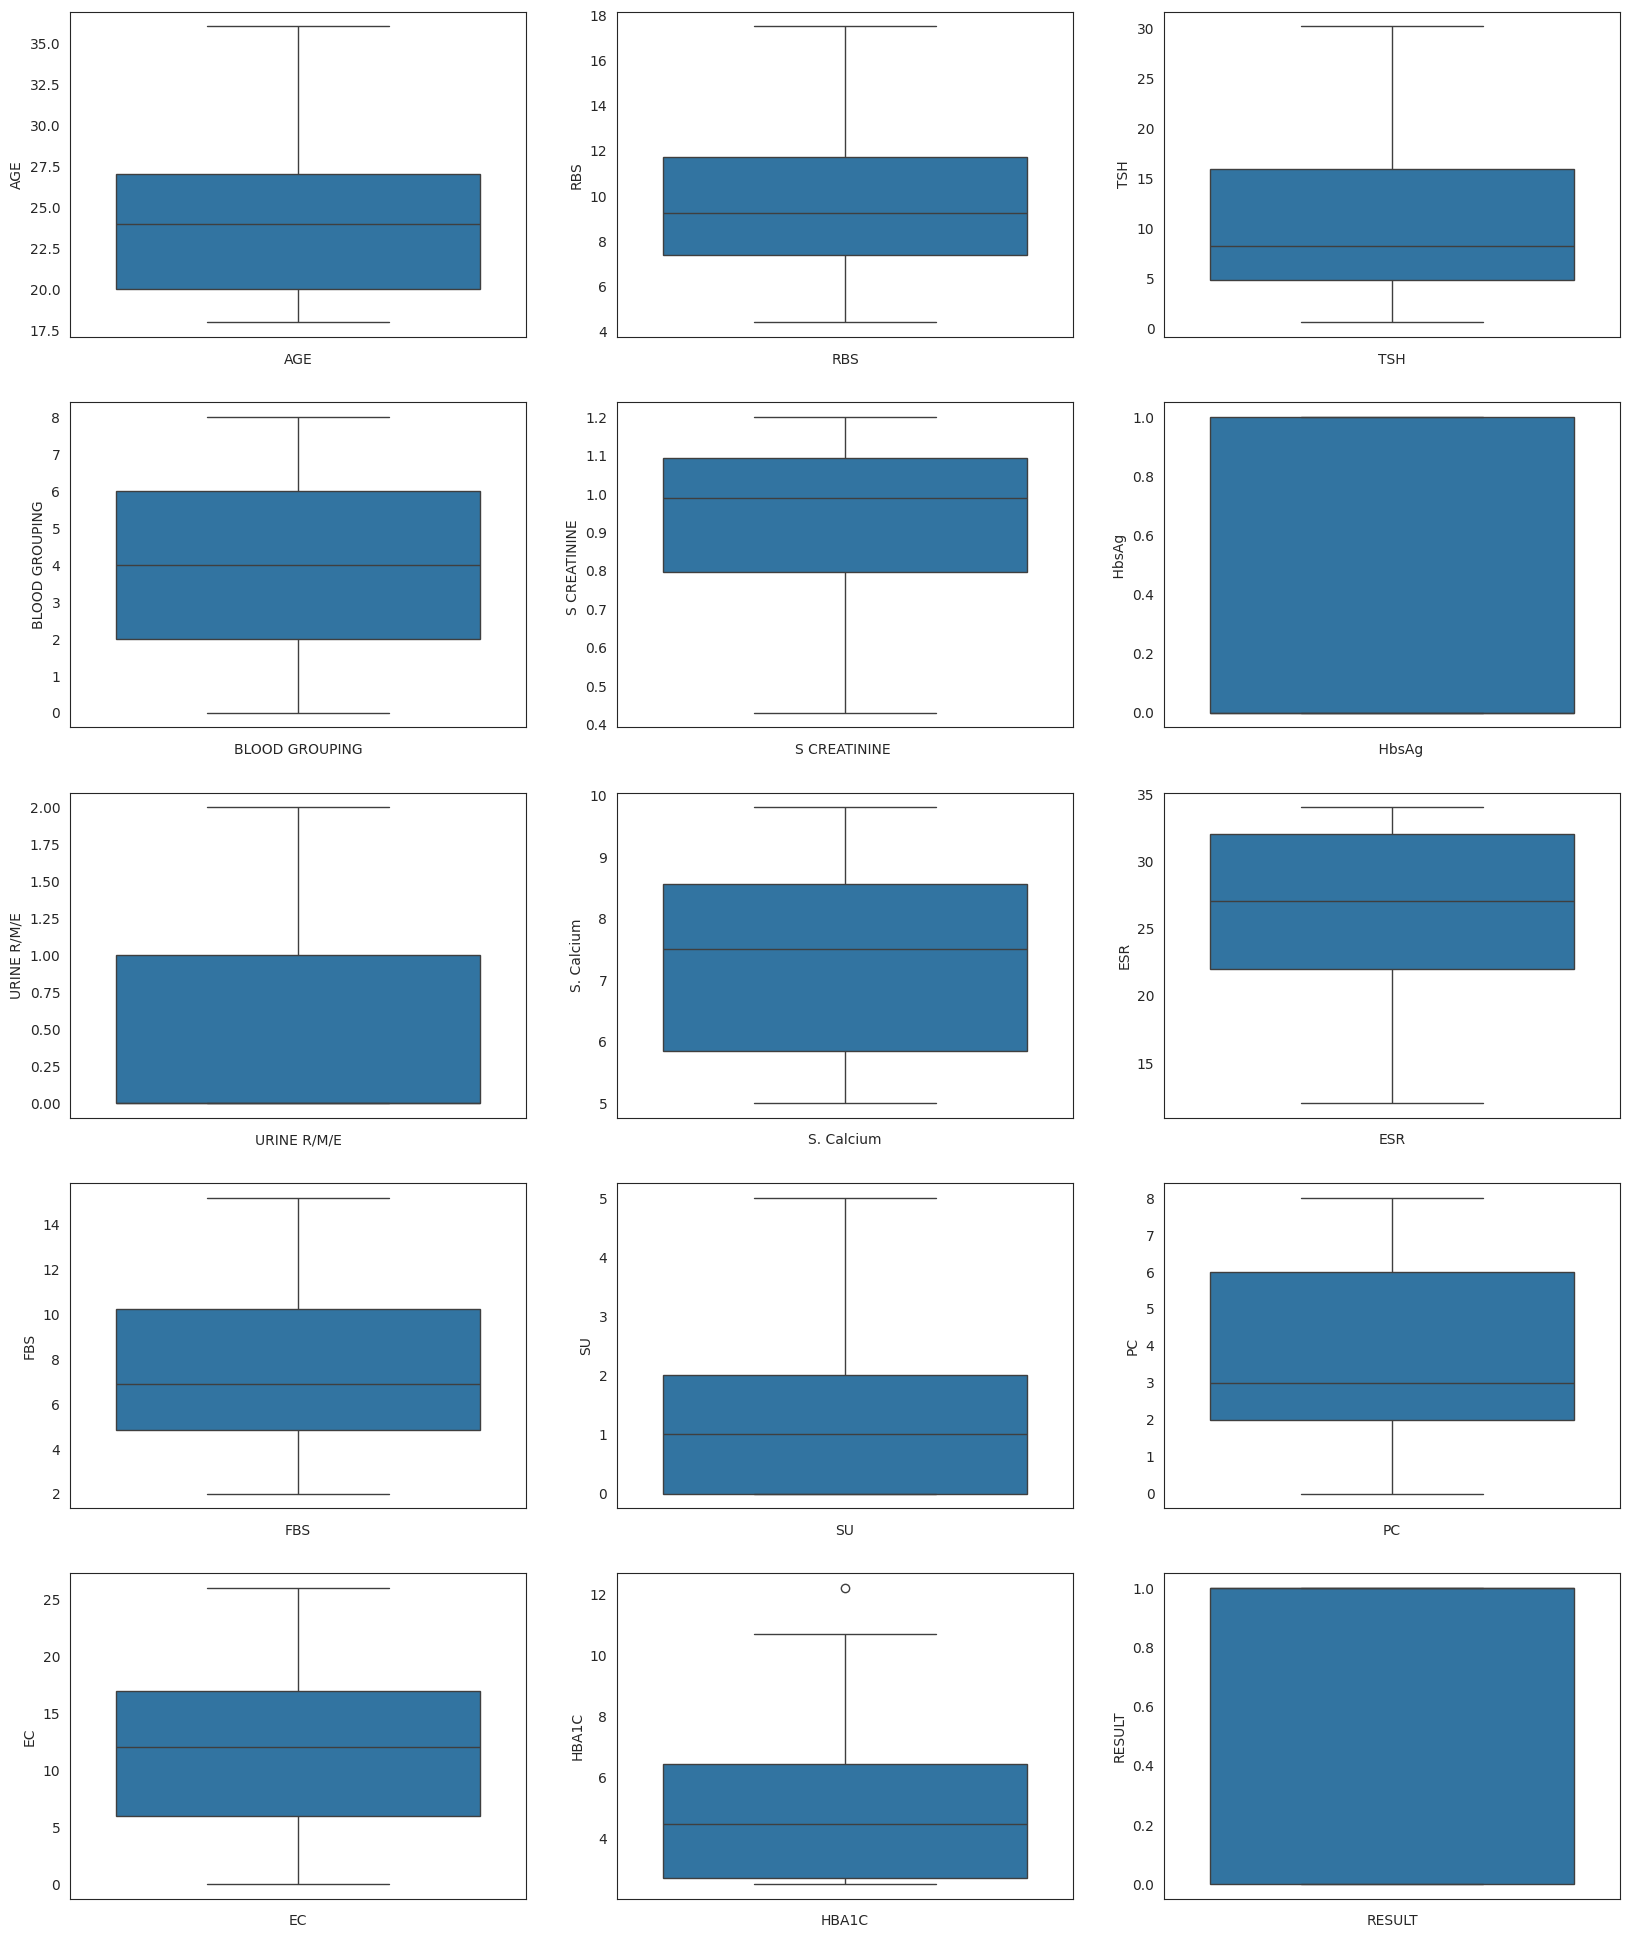

In [ ]:
plt.figure(figsize=(20,60),facecolor='white')
plotnumber=1
for numerical_feature in numerical_features:
    ax=plt.subplot(12,3,plotnumber)
    sns.boxplot(df1[numerical_feature])
    plt.xlabel(numerical_feature)
    plotnumber+=1
plt.show()

In [ ]:
for col in df1.columns:
    print(col)

AGE
RBS
TSH
BLOOD GROUPING
S CREATININE 
    HbsAg
URINE R/M/E
S. Calcium
ESR
FBS
SU
PC
EC
HBA1C
RESULT


In [ ]:
for col in df:
    print({col: df[col].unique()})

{'AGE': array([18, 25, 30, 20, 28, 23, 36, 21, 26, 24, 22, 27, 31, 29, 34, 32, 19,
       33, 35])}
{'RBS': array([ 8.5,  8.2, 12.7,  5.6,  4.4,  5.5,  9.8, 10.8,  6. ,  4.9,  9.5,
       14.1,  8.7,  9.4, 10.2,  5.8,  7.7,  4.7,  4.6, 13. , 10.1, 10.5,
       16. ,  9.2,  8.4,  7.4,  7.5,  7.6,  7.8,  7. ,  6.1,  8.6, 12.9,
       10.9,  7.3, 12.8,  9.6,  4.8, 10.6,  8.8, 12.5,  6.2,  7.9, 14.5,
       12.6, 12.3,  8.1,  5. , 11.8, 11.1, 10.3, 12.4,  6.6, 14. ,  6.4,
       15.7,  5.1, 12. ,  8.3, 11.9, 15.2,  5.4,  6.8, 17.1, 10.7, 11.5,
        6.3, 12.2,  9.3, 11.3, 14.6,  9.1,  8. ,  7.2,  8.9, 15. , 11.6,
       11.7, 14.4, 15.3,  9. ,  5.3, 16.3,  9.7, 13.7, 10. , 13.2,  5.2,
       10.4, 14.8, 11.2, 11.4, 11. , 17.5, 13.1, 17. ])}
{'TSH': array([11.14,  2.69, 30.2 , 29.82,  5.72, 20.76,  6.49,  7.53,  1.06,
        6.47, 16.64,  3.68,  7.31, 10.14,  8.01, 26.2 ,  5.51,  1.41,
       21.3 ,  4.38,  8.59,  3.  ,  9.99, 22.55,  0.6 ,  3.14,  8.13,
        8.52,  5.56,  3.64,  8.02

In [ ]:
#segregating dataset into features i.e.. X and target variables i.e.., y
X=df.drop(['RESULT'],axis=1)
y=df['RESULT']

<Axes: title={'center': 'Correlation of self medication'}>

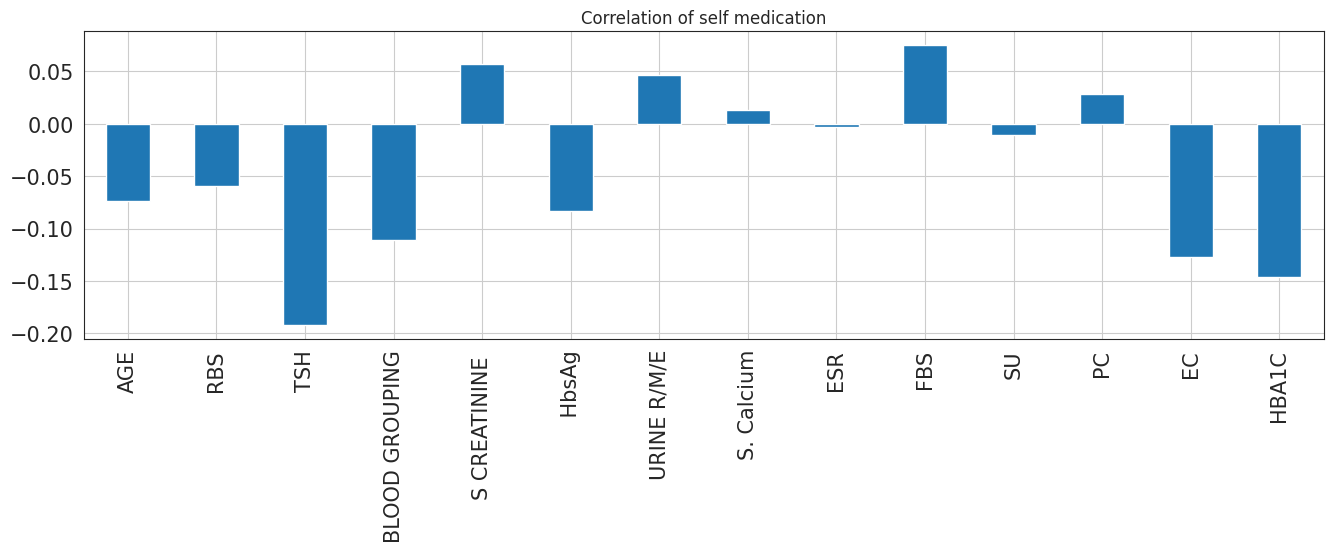

In [ ]:
#Correlation with Response Variable class
X.corrwith(y).plot.bar(
        figsize=(16,4),title="Correlation of self medication", fontsize=15,rot=90,grid=True)

In [ ]:
y.value_counts()

,count
RESULT,
1,118
0,82


In [ ]:
#Smote for Balancing Data
from imblearn.over_sampling import SMOTE
smote =SMOTE(random_state=42)
X_sm,y_sm =smote.fit_resample(X,y)

In [ ]:
y_sm.value_counts()

,count
RESULT,
1,118
0,118


[None, None]

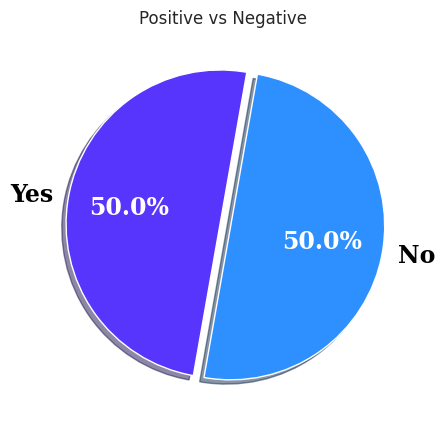

In [ ]:
status_data=y_sm.value_counts()

explode=(0.02,0.05)
pie_colors=('#5735FD','#2E90FF')

plt.figure(figsize=(5,5))
plt.title("Positive vs Negative")
patches,texts,pcts = plt.pie(status_data,labels=['Yes','No'],
                            explode=explode,colors=pie_colors,
                            shadow=True,
                            startangle=80,
                            autopct='%0.1f%%',
                            textprops={'fontsize':17,
                                      'color':'black',
                                      'weight':'bold',
                                      'family':'serif'})

plt.setp(pcts,color='white')

In [ ]:
#Train_Test_split ->,
X_train,X_test,y_train,y_test = train_test_split(X_sm,y_sm,stratify=y_sm,test_size=0.20,shuffle=True,random_state=20)

In [ ]:
print("Input Training",X_train.shape)
print("Input Test",X_test.shape)
print("="*30)
print("Output Training",y_train.shape)
print("Output Test",y_test.shape)

Input Training (188, 14)
Input Test (48, 14)
Output Training (188,)
Output Test (48,)


In [ ]:
X_train.head()

,AGE,RBS,TSH,BLOOD GROUPING,S CREATININE,HbsAg,URINE R/M/E,S. Calcium,ESR,FBS,SU,PC,EC,HBA1C
221,26,8.823801,3.40444,4,0.726998,1,0,9.243037,21,10.633872,1,4,23,4.343233
138,24,11.700000,12.33000,4,0.960000,0,1,9.550000,27,2.510000,0,6,2,4.360000
58,29,6.200000,8.10000,2,1.020000,0,0,5.000000,20,11.790000,2,3,1,4.420000
188,20,11.700000,16.28000,5,1.200000,0,0,6.890000,18,4.470000,2,4,21,6.170000
122,28,10.100000,24.14000,1,1.030000,1,0,8.890000,21,2.630000,2,1,12,2.500000


In [ ]:
X_test.head()

,AGE,RBS,TSH,BLOOD GROUPING,S CREATININE,HbsAg,URINE R/M/E,S. Calcium,ESR,FBS,SU,PC,EC,HBA1C
116,18,8.000000,8.040000,4,1.07000,0,0,6.680000,33,4.020000,0,2,15,8.260000
40,31,10.900000,6.430000,2,0.80000,1,0,5.000000,32,11.760000,2,3,0,4.960000
32,22,7.600000,17.840000,7,1.16000,0,1,6.110000,27,9.190000,0,4,15,7.630000
208,21,7.867474,25.439143,1,1.00528,1,1,6.597259,27,4.547232,0,6,15,5.621952
171,24,10.700000,2.590000,5,0.44000,1,0,6.850000,23,5.610000,5,4,15,2.500000


In [ ]:
#KNN
knn =KNN()
knn.fit(X_train,y_train)
y_pred_knn=knn.predict(X_test)

#DecisionTreeClassifier
dtree=DecisionTreeClassifier()
dtree.fit(X_train,y_train)
y_pred_dtree=dtree.predict(X_test)

#RandomForestClassifier
rtree=RandomForestClassifier(n_estimators=10,random_state=0,criterion='entropy',
                             max_depth=10, max_features='log2')
rtree.fit(X_train,y_train)
y_pred_rtree=rtree.predict(X_test)
#SVC
C=1.0
svm=SVC(probability=True,kernel='rbf',gamma=0.7,C=C)
svm.fit(X_train,y_train)
y_pred_svm=svm.predict(X_test)

import xgboost as xgb
#XGBClassifier
xgb=xgb.XGBClassifier()
xgb.fit(X_train,y_train)
y_pred_xgb=xgb.predict(X_test)

#MLPClassifier
Mlp=MLPClassifier(hidden_layer_sizes=500, activation='relu', solver='adam')
Mlp.fit(X_train,y_train)
y_pred_mlp=Mlp.predict(X_test)

,Model,Accuracy,Precision,Sensitivity,specificity,F1 Score,ROC,Recall,Log_Loss,mathew_corrcoef,kappa,MissClassificationError
0,KNN,47.92,47.62,41.67,54.17,44.44,47.92,41.67,18.77,-4.2,-4.17,52.08


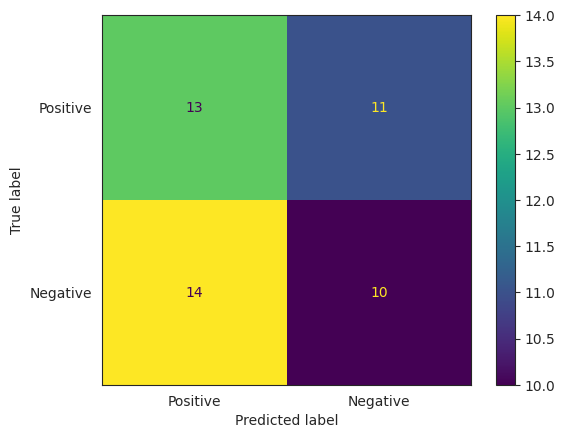

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
labels=['Positive','Negative']
CM=confusion_matrix(y_test,y_pred_knn)
ConfusionMatrixDisplay(CM,display_labels=labels).plot()

TN=CM[0][0]
FN=CM[1][0]
TP=CM[1][1]
FP=CM[0][1]

senstivity= round(TP/(FN+TP)*100,2)
specificity = round(TN/(TN+FP)*100,2)
loss_log = round(log_loss(y_test,y_pred_knn),2)
acc=round(accuracy_score(y_test,y_pred_knn)*100,2)
roc=round(roc_auc_score(y_test,y_pred_knn)*100,2)
prec=round(precision_score(y_test,y_pred_knn)*100,2)
rec=round(recall_score(y_test,y_pred_knn)*100,2)
f1=round(f1_score(y_test,y_pred_knn)*100,2)
kappa1=round(cohen_kappa_score(y_test,y_pred_knn)*100,2)
mathew = round(matthews_corrcoef(y_test,y_pred_knn)*100,2)

misscerr=round((FP+FN)/(TP+TN+FP+FN)*100,2)#(1-Accuracy)

model_results =pd.DataFrame([['KNN',acc,prec,senstivity,specificity,f1,roc,rec,loss_log,mathew,kappa1,misscerr]],
                           columns=['Model','Accuracy','Precision','Sensitivity','specificity','F1 Score','ROC','Recall','Log_Loss','mathew_corrcoef','kappa','MissClassificationError'])

model_results

In [ ]:
data={
            'XGB':y_pred_xgb,
            'SVC':y_pred_svm,
            'DTC':y_pred_dtree,
            'RFC':y_pred_rtree,
            'MLP':y_pred_mlp,


}

models = pd.DataFrame(data)

for column in models:
    CM = confusion_matrix(y_test,models[column])

    TN=CM[0][0]
    FN=CM[1][0]
    TP=CM[1][1]
    FP=CM[0][1]


    senstivity=round(TP/(FN+TP)*100,2)
    specificity = round(TN/(TN+FP)*100,2)
    loss_log =round (log_loss(y_test,models[column]),2)
    acc=round(accuracy_score(y_test,models[column])*100,2)
    roc=round(roc_auc_score(y_test,models[column])*100,2)
    prec=round(precision_score(y_test,models[column])*100,2)
    rec=round(recall_score(y_test,models[column])*100,2)
    f1=round(f1_score(y_test,models[column])*100,2)
    mathew = round(matthews_corrcoef(y_test,models[column])*100,2)
    kappa2= round(cohen_kappa_score(y_test,models[column])*100,2)

    misscerr=round((FP+FN)/(TP+TN+FP+FN)*100,2)#(1-Accuracy)

    results =pd.DataFrame([[column,acc,prec,senstivity,specificity,f1,roc,rec,loss_log,mathew,kappa2,misscerr]],
                            columns=['Model','Accuracy','Precision','Sensitivity','specificity','F1 Score','ROC','Recall','Log_Loss','mathew_corrcoef','kappa','MissClassificationError'])
    model_results = pd.concat([model_results, results], ignore_index=True)

model_results

,Model,Accuracy,Precision,Sensitivity,specificity,F1 Score,ROC,Recall,Log_Loss,mathew_corrcoef,kappa,MissClassificationError
0,KNN,47.92,47.62,41.67,54.17,44.44,47.92,41.67,18.77,-4.20,-4.17,52.08
1,XGB,52.08,52.17,50.00,54.17,51.06,52.08,50.00,17.27,4.17,4.17,47.92
2,SVC,62.50,57.14,100.00,25.00,72.73,62.50,100.00,13.52,37.80,25.00,37.50
3,DTC,47.92,48.00,50.00,45.83,48.98,47.92,50.00,18.77,-4.17,-4.17,52.08
4,RFC,60.42,61.90,54.17,66.67,57.78,60.42,54.17,14.27,21.00,20.83,39.58
5,MLP,54.17,55.00,45.83,62.50,50.00,54.17,45.83,16.52,8.45,8.33,45.83


In [ ]:
from mlxtend.classifier import EnsembleVoteClassifier

In [ ]:
clfs=[svm,Mlp]
model_clfs=EnsembleVoteClassifier(
    clfs=clfs,
    voting="soft",
    weights=[1,1],
    fit_base_estimators=False
).fit(X_train,y_train)

pred_clfs=model_clfs.predict(X_test)

,Model,Accuracy,Precision,Sensitivity,specificity,F1 Score,ROC,Recall,Log_Loss,mathew_corrcoef,kappa,MissClassificationError
0,Hybrid Model (SVM+MLP),52.08,52.38,45.83,58.33,48.89,52.08,45.83,17.27,4.2,4.17,47.92


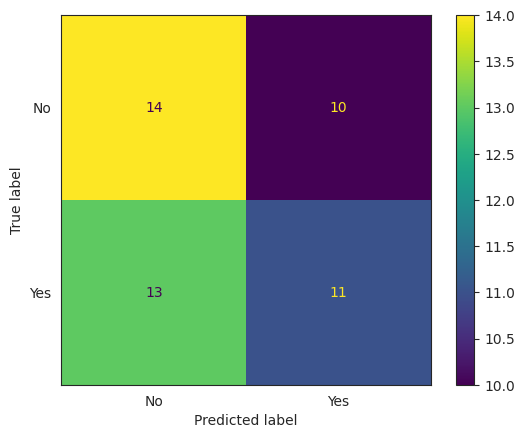

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
labels=['No','Yes']
CM=confusion_matrix(y_test,pred_clfs)
ConfusionMatrixDisplay(CM,display_labels=labels).plot()

TN=CM[0][0]
FN=CM[1][0]
TP=CM[1][1]
FP=CM[0][1]

senstivity= round(TP/(FN+TP)*100,2)
specificity = round(TN/(TN+FP)*100,2)
loss_log = round(log_loss(y_test,pred_clfs),2)
acc=round(accuracy_score(y_test,pred_clfs)*100,2)
roc=round(roc_auc_score(y_test,pred_clfs)*100,2)
prec=round(precision_score(y_test,pred_clfs)*100,2)
rec=round(recall_score(y_test,pred_clfs)*100,2)
f1=round(f1_score(y_test,pred_clfs)*100,2)
kappa1=round(cohen_kappa_score(y_test,pred_clfs)*100,2)
mathew = round(matthews_corrcoef(y_test,pred_clfs)*100,2)

misscerr=round((FP+FN)/(TP+TN+FP+FN)*100,2)#(1-Accuracy)

Hybrid_Model_results =pd.DataFrame([['Hybrid Model (SVM+MLP)',acc,prec,senstivity,specificity,f1,roc,rec,loss_log,mathew,kappa1,misscerr]],
                           columns=['Model','Accuracy','Precision','Sensitivity','specificity','F1 Score','ROC','Recall','Log_Loss','mathew_corrcoef','kappa','MissClassificationError'])

Hybrid_Model_results

In [ ]:
all_model_results=pd.concat([Hybrid_Model_results,model_results],ignore_index = True) # Use concat instead of append

In [ ]:
clfs1=[rtree,Mlp]
model_clfs1=EnsembleVoteClassifier(
    clfs=clfs1,
    voting="soft",
    weights=[1,1],
    fit_base_estimators=False
).fit(X_train,y_train)

pred_clfs1=model_clfs1.predict(X_test)

,Model,Accuracy,Precision,Sensitivity,specificity,F1 Score,ROC,Recall,Log_Loss,mathew_corrcoef,kappa,MissClassificationError
0,Hybrid Model (RFC+MLP),62.5,63.64,58.33,66.67,60.87,62.5,58.33,13.52,25.09,25.0,37.5


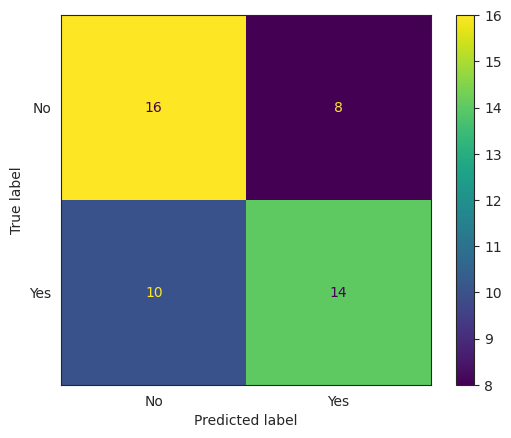

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
labels=['No','Yes']
CM=confusion_matrix(y_test,pred_clfs1)
ConfusionMatrixDisplay(CM,display_labels=labels).plot()

TN=CM[0][0]
FN=CM[1][0]
TP=CM[1][1]
FP=CM[0][1]

senstivity= round(TP/(FN+TP)*100,2)
specificity = round(TN/(TN+FP)*100,2)
loss_log = round(log_loss(y_test,pred_clfs1),2)
acc=round(accuracy_score(y_test,pred_clfs1)*100,2)
roc=round(roc_auc_score(y_test,pred_clfs1)*100,2)
prec=round(precision_score(y_test,pred_clfs1)*100,2)
rec=round(recall_score(y_test,pred_clfs1)*100,2)
f1=round(f1_score(y_test,pred_clfs1)*100,2)
kappa1=round(cohen_kappa_score(y_test,pred_clfs1)*100,2)
mathew = round(matthews_corrcoef(y_test,pred_clfs1)*100,2)

misscerr=round((FP+FN)/(TP+TN+FP+FN)*100,2)#(1-Accuracy)

Hybrid_Model_results1 =pd.DataFrame([['Hybrid Model (RFC+MLP)',acc,prec,senstivity,specificity,f1,roc,rec,loss_log,mathew,kappa1,misscerr]],
                           columns=['Model','Accuracy','Precision','Sensitivity','specificity','F1 Score','ROC','Recall','Log_Loss','mathew_corrcoef','kappa','MissClassificationError'])

Hybrid_Model_results1

In [ ]:
# Use concat to combine DataFrames instead of append
all_model_results = pd.concat([Hybrid_Model_results1, all_model_results], ignore_index=True)
all_model_results

,Model,Accuracy,Precision,Sensitivity,specificity,F1 Score,ROC,Recall,Log_Loss,mathew_corrcoef,kappa,MissClassificationError
0,Hybrid Model (RFC+MLP),62.50,63.64,58.33,66.67,60.87,62.50,58.33,13.52,25.09,25.00,37.50
1,Hybrid Model (SVM+MLP),52.08,52.38,45.83,58.33,48.89,52.08,45.83,17.27,4.20,4.17,47.92
2,KNN,47.92,47.62,41.67,54.17,44.44,47.92,41.67,18.77,-4.20,-4.17,52.08
3,XGB,52.08,52.17,50.00,54.17,51.06,52.08,50.00,17.27,4.17,4.17,47.92
4,SVC,62.50,57.14,100.00,25.00,72.73,62.50,100.00,13.52,37.80,25.00,37.50
5,DTC,47.92,48.00,50.00,45.83,48.98,47.92,50.00,18.77,-4.17,-4.17,52.08
6,RFC,60.42,61.90,54.17,66.67,57.78,60.42,54.17,14.27,21.00,20.83,39.58
7,MLP,54.17,55.00,45.83,62.50,50.00,54.17,45.83,16.52,8.45,8.33,45.83


In [ ]:
clfs2=[xgb,Mlp]
model_clfs2=EnsembleVoteClassifier(
    clfs=clfs2,
    voting="soft",
    weights=[1,1],
    fit_base_estimators=False
).fit(X_train,y_train)

pred_clfs2=model_clfs2.predict(X_test)

,Model,Accuracy,Precision,Sensitivity,specificity,F1 Score,ROC,Recall,Log_Loss,mathew_corrcoef,kappa,MissClassificationError
0,Hybrid Model (xgb+MLP),62.5,63.64,58.33,66.67,60.87,62.5,58.33,13.52,25.09,25.0,37.5


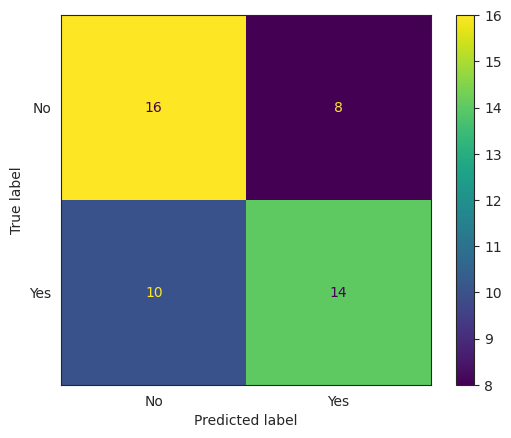

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
labels=['No','Yes']
CM=confusion_matrix(y_test,pred_clfs2)
ConfusionMatrixDisplay(CM,display_labels=labels).plot()

TN=CM[0][0]
FN=CM[1][0]
TP=CM[1][1]
FP=CM[0][1]

senstivity= round(TP/(FN+TP)*100,2)
specificity = round(TN/(TN+FP)*100,2)
loss_log = round(log_loss(y_test,pred_clfs2),2)
acc=round(accuracy_score(y_test,pred_clfs2)*100,2)
roc=round(roc_auc_score(y_test,pred_clfs2)*100,2)
prec=round(precision_score(y_test,pred_clfs2)*100,2)
rec=round(recall_score(y_test,pred_clfs2)*100,2)
f1=round(f1_score(y_test,pred_clfs2)*100,2)
kappa1=round(cohen_kappa_score(y_test,pred_clfs2)*100,2)
mathew = round(matthews_corrcoef(y_test,pred_clfs2)*100,2)

misscerr=round((FP+FN)/(TP+TN+FP+FN)*100,2)#(1-Accuracy)

Hybrid_Model_results2 =pd.DataFrame([['Hybrid Model (xgb+MLP)',acc,prec,senstivity,specificity,f1,roc,rec,loss_log,mathew,kappa1,misscerr]],
                           columns=['Model','Accuracy','Precision','Sensitivity','specificity','F1 Score','ROC','Recall','Log_Loss','mathew_corrcoef','kappa','MissClassificationError'])

Hybrid_Model_results2

In [ ]:
all_model_results = pd.concat([Hybrid_Model_results2, all_model_results], ignore_index=True)
all_model_results

,Model,Accuracy,Precision,Sensitivity,specificity,F1 Score,ROC,Recall,Log_Loss,mathew_corrcoef,kappa,MissClassificationError
0,Hybrid Model (xgb+MLP),62.50,63.64,58.33,66.67,60.87,62.50,58.33,13.52,25.09,25.00,37.50
1,Hybrid Model (RFC+MLP),62.50,63.64,58.33,66.67,60.87,62.50,58.33,13.52,25.09,25.00,37.50
2,Hybrid Model (SVM+MLP),52.08,52.38,45.83,58.33,48.89,52.08,45.83,17.27,4.20,4.17,47.92
3,KNN,47.92,47.62,41.67,54.17,44.44,47.92,41.67,18.77,-4.20,-4.17,52.08
4,XGB,52.08,52.17,50.00,54.17,51.06,52.08,50.00,17.27,4.17,4.17,47.92
5,SVC,62.50,57.14,100.00,25.00,72.73,62.50,100.00,13.52,37.80,25.00,37.50
6,DTC,47.92,48.00,50.00,45.83,48.98,47.92,50.00,18.77,-4.17,-4.17,52.08
7,RFC,60.42,61.90,54.17,66.67,57.78,60.42,54.17,14.27,21.00,20.83,39.58
8,MLP,54.17,55.00,45.83,62.50,50.00,54.17,45.83,16.52,8.45,8.33,45.83


In [ ]:
# Use the already trained RandomForestClassifier (rtree) to get feature importances
feature_importances = rtree.feature_importances_

# Create a DataFrame to display the feature importances
features_df = pd.DataFrame({'Feature': X_sm.columns, 'Importance': feature_importances})

# Sort the features by importance in descending order
features_df = features_df.sort_values(by='Importance', ascending=False)

# Display the feature importances
display(features_df)

,Feature,Importance
1,RBS,0.105916
9,FBS,0.103354
13,HBA1C,0.099673
12,EC,0.092876
2,TSH,0.091077
4,S CREATININE,0.084931
7,S. Calcium,0.084237
8,ESR,0.077160
0,AGE,0.071866
3,BLOOD GROUPING,0.070955


In [ ]:
# XGBoost Feature Importance - Fixed & Robust

# Option 1: Most common fix (if using XGBClassifier or XGBRegressor)
feature_importances = xgb.feature_importances_

features_df_xgb = pd.DataFrame({
    'Feature': X_sm.columns,
    'Importance': feature_importances
})

features_df_xgb = features_df_xgb.sort_values(by='Importance', ascending=False)\
                 .reset_index(drop=True)

display(features_df_xgb)
print(f"Shape: {features_df_xgb.shape}")

,Feature,Importance
0,FBS,0.094401
1,BLOOD GROUPING,0.093872
2,AGE,0.086814
3,TSH,0.085262
4,HBA1C,0.083342
5,RBS,0.079447
6,S CREATININE,0.078486
7,PC,0.077369
8,EC,0.071023
9,S. Calcium,0.067233


Shape: (14, 2)


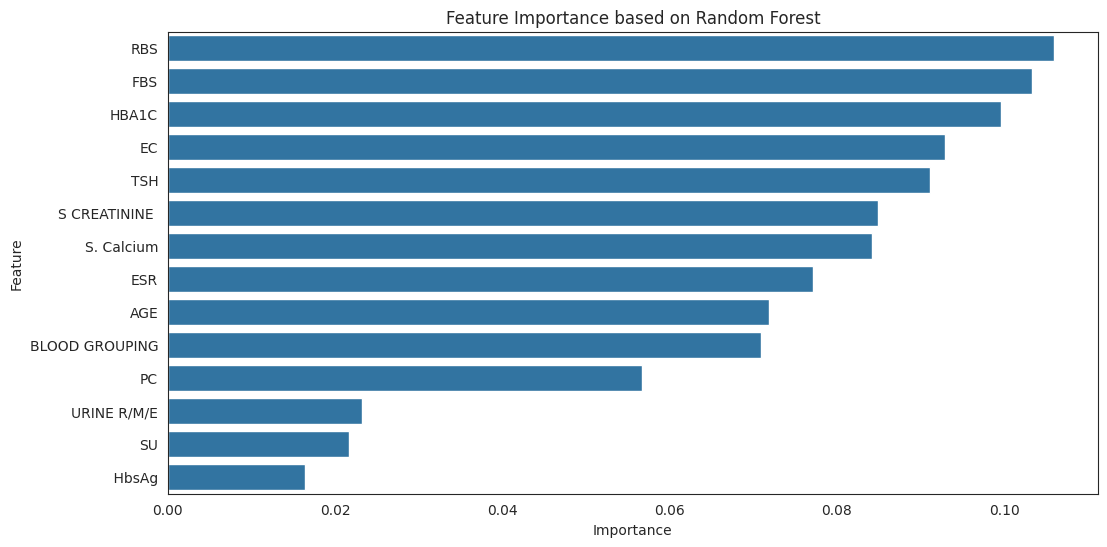

In [ ]:
plt.figure(figsize=(6, 6))
sns.barplot(x='Importance', y='Feature', data=features_df)
plt.title('Feature Importance based on XGBoost')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

In [ ]:
# LGBMClassifier
lgbm = LGBMClassifier(random_state=42)
lgbm.fit(X_train, y_train)
y_pred_lgbm = lgbm.predict(X_test)

# Evaluate LGBMClassifier
CM = confusion_matrix(y_test, y_pred_lgbm)

TN = CM[0][0]
FN = CM[1][0]
TP = CM[1][1]
FP = CM[0][1]

senstivity = round(TP / (FN + TP) * 100, 2)
specificity = round(TN / (TN + FP) * 100, 2)
loss_log = round(log_loss(y_test, y_pred_lgbm), 2)
acc = round(accuracy_score(y_test, y_pred_lgbm) * 100, 2)
roc = round(roc_auc_score(y_test, y_pred_lgbm) * 100, 2)
prec = round(precision_score(y_test, y_pred_lgbm) * 100, 2)
rec = round(recall_score(y_test, y_pred_lgbm) * 100, 2)
f1 = round(f1_score(y_test, y_pred_lgbm) * 100, 2)
mathew = round(matthews_corrcoef(y_test, y_pred_lgbm) * 100, 2)
kappa = round(cohen_kappa_score(y_test, y_pred_lgbm) * 100, 2)

misscerr = round((FP + FN) / (TP + TN + FP + FN) * 100, 2)

lgbm_results = pd.DataFrame([['LGBMClassifier', acc, prec, senstivity, specificity, f1, roc, rec, loss_log, mathew, kappa, misscerr]],
                           columns=['Model', 'Accuracy', 'Precision', 'Sensitivity', 'specificity', 'F1 Score', 'ROC', 'Recall', 'Log_Loss', 'mathew_corrcoef', 'kappa', 'MissClassificationError'])

# Add LGBM results to the all_model_results DataFrame
all_model_results = pd.concat([all_model_results, lgbm_results], ignore_index=True)

# Display the updated results
all_model_results

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 94, number of negative: 94
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000333 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 408
[LightGBM] [Info] Number of data points in the train set: 188, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits w

,Model,Accuracy,Precision,Sensitivity,specificity,F1 Score,ROC,Recall,Log_Loss,mathew_corrcoef,kappa,MissClassificationError
0,Hybrid Model (xgb+MLP),62.50,63.64,58.33,66.67,60.87,62.50,58.33,13.52,25.09,25.00,37.50
1,Hybrid Model (RFC+MLP),62.50,63.64,58.33,66.67,60.87,62.50,58.33,13.52,25.09,25.00,37.50
2,Hybrid Model (SVM+MLP),52.08,52.38,45.83,58.33,48.89,52.08,45.83,17.27,4.20,4.17,47.92
3,KNN,47.92,47.62,41.67,54.17,44.44,47.92,41.67,18.77,-4.20,-4.17,52.08
4,XGB,52.08,52.17,50.00,54.17,51.06,52.08,50.00,17.27,4.17,4.17,47.92
5,SVC,62.50,57.14,100.00,25.00,72.73,62.50,100.00,13.52,37.80,25.00,37.50
6,DTC,47.92,48.00,50.00,45.83,48.98,47.92,50.00,18.77,-4.17,-4.17,52.08
7,RFC,60.42,61.90,54.17,66.67,57.78,60.42,54.17,14.27,21.00,20.83,39.58
8,MLP,54.17,55.00,45.83,62.50,50.00,54.17,45.83,16.52,8.45,8.33,45.83
9,LGBMClassifier,60.42,59.26,66.67,54.17,62.75,60.42,66.67,14.27,21.00,20.83,39.58


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   AGE             200 non-null    int64  
 1   RBS             200 non-null    float64
 2   TSH             200 non-null    float64
 3   BLOOD GROUPING  200 non-null    int64  
 4   S CREATININE    200 non-null    float64
 5       HbsAg       200 non-null    int64  
 6   URINE R/M/E     200 non-null    int64  
 7   S. Calcium      200 non-null    float64
 8   ESR             200 non-null    int64  
 9   FBS             200 non-null    float64
 10  SU              200 non-null    int64  
 11  PC              200 non-null    int64  
 12  EC              200 non-null    int64  
 13  HBA1C           200 non-null    float64
 14  RESULT          200 non-null    int64  
dtypes: float64(6), int64(9)
memory usage: 23.6 KB


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create a LabelEncoder object
le = LabelEncoder()

# Iterate through each column
for col in df.columns:
    # Check if the data type is 'object'
    if df[col].dtype == 'object':
        # Apply label encoding and overwrite the original column
        df[col] = le.fit_transform(df[col])

# Display the first few rows of the DataFrame to verify the conversion
df.head()

,AGE,RBS,TSH,BLOOD GROUPING,S CREATININE,HbsAg,URINE R/M/E,S. Calcium,ESR,FBS,SU,PC,EC,HBA1C,RESULT
0,18,8.5,11.14,1,1.02,0,0,5.18,26,5.17,0,7,1,6.52,1
1,25,8.2,2.69,6,0.89,1,1,8.80,34,11.21,2,6,5,8.11,0
2,30,12.7,30.20,5,1.14,0,0,8.42,22,5.80,0,2,20,2.50,0
3,20,5.6,29.82,7,0.50,1,1,9.46,17,12.76,0,0,25,2.79,0
4,28,4.4,5.72,0,0.51,1,1,5.00,24,11.34,0,3,3,2.50,1


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create a LabelEncoder object
le = LabelEncoder()

# Iterate through each column
for col in df.columns:
    # Check if the data type is 'object'
    if df[col].dtype == 'object':
        # Convert all values to string type before label encoding
        df[col] = df[col].astype(str)
        # Apply label encoding and overwrite the original column
        df[col] = le.fit_transform(df[col])

# Display the first few rows of the DataFrame to verify the conversion
df.head()

,AGE,RBS,TSH,BLOOD GROUPING,S CREATININE,HbsAg,URINE R/M/E,S. Calcium,ESR,FBS,SU,PC,EC,HBA1C,RESULT
0,18,8.5,11.14,1,1.02,0,0,5.18,26,5.17,0,7,1,6.52,1
1,25,8.2,2.69,6,0.89,1,1,8.80,34,11.21,2,6,5,8.11,0
2,30,12.7,30.20,5,1.14,0,0,8.42,22,5.80,0,2,20,2.50,0
3,20,5.6,29.82,7,0.50,1,1,9.46,17,12.76,0,0,25,2.79,0
4,28,4.4,5.72,0,0.51,1,1,5.00,24,11.34,0,3,3,2.50,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   AGE             200 non-null    int64  
 1   RBS             200 non-null    float64
 2   TSH             200 non-null    float64
 3   BLOOD GROUPING  200 non-null    int64  
 4   S CREATININE    200 non-null    float64
 5       HbsAg       200 non-null    int64  
 6   URINE R/M/E     200 non-null    int64  
 7   S. Calcium      200 non-null    float64
 8   ESR             200 non-null    int64  
 9   FBS             200 non-null    float64
 10  SU              200 non-null    int64  
 11  PC              200 non-null    int64  
 12  EC              200 non-null    int64  
 13  HBA1C           200 non-null    float64
 14  RESULT          200 non-null    int64  
dtypes: float64(6), int64(9)
memory usage: 23.6 KB
